In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
from pathlib import Path
import numpy as np

In [2]:
from pce import data, returns, estimators, optimize

rets = data.load_returns()
weekly_returns = returns.to_weekly(rets)
risky_returns = returns.risky_returns(weekly_returns)
excess_returns = returns.excess_returns(weekly_returns)

corr = estimators.correlation(excess_returns)
lw_cov = estimators.ledoit_wolf_covariance(excess_returns)[0]

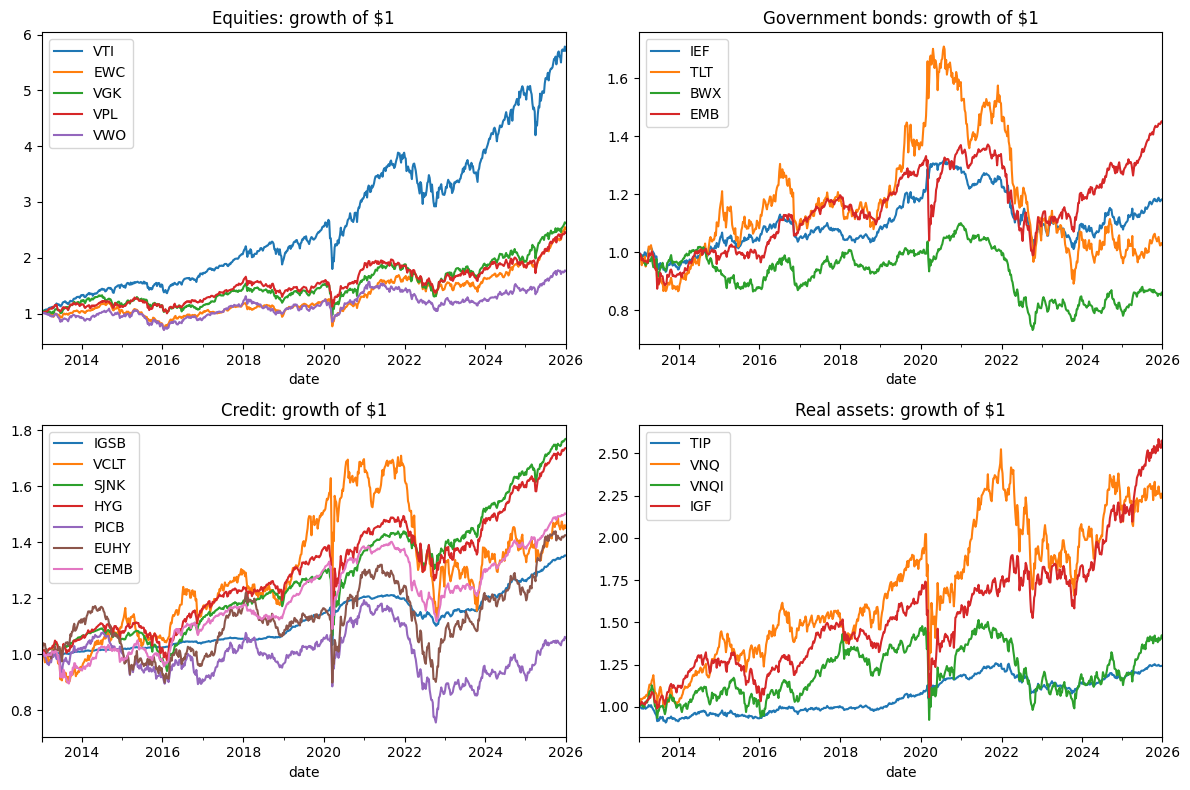

In [3]:
import matplotlib.pyplot as plt

blocks = {
    "Equities": ["VTI", "EWC", "VGK", "VPL", "VWO"],
    "Government bonds": ["IEF", "TLT", "BWX", "EMB"],
    "Credit": ["IGSB", "VCLT", "SJNK", "HYG", "PICB", "EUHY", "CEMB"],
    "Real assets": ["TIP", "VNQ", "VNQI", "IGF"],
}

# Growth of $1
growth = (1 + risky_returns).cumprod()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (name, cols) in zip(axes.flat, blocks.items()):
    growth[cols].plot(ax=ax, title=f"{name}: growth of $1")
plt.tight_layout()

Text(0.5, 1.0, 'Weekly excess-return Ledoit-Wolf Correlations')

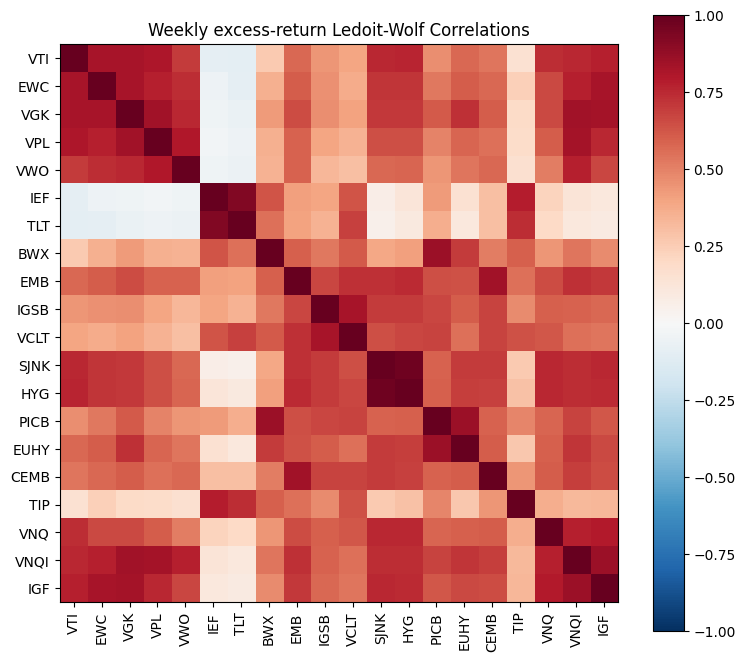

In [4]:
plt.figure(figsize=(9, 8))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(lw_cov)), lw_cov.columns, rotation=90)
plt.yticks(range(len(lw_cov)), lw_cov.columns)
plt.colorbar()
plt.title("Weekly excess-return Ledoit-Wolf Correlations")

In [5]:
w = optimize.min_variance(lw_cov)[0]
variance = w @ lw_cov @ w
vol = np.sqrt(variance)

exp_ret = returns.sample_expected_returns(excess_returns)
min_vol_ret = w @ exp_ret
max_ret = np.max(exp_ret)
y_axis = np.linspace(min_vol_ret, max_ret)
efficient_frontier = [optimize.min_variance(lw_cov, 1, exp_ret, x)[1] for x in y_axis]


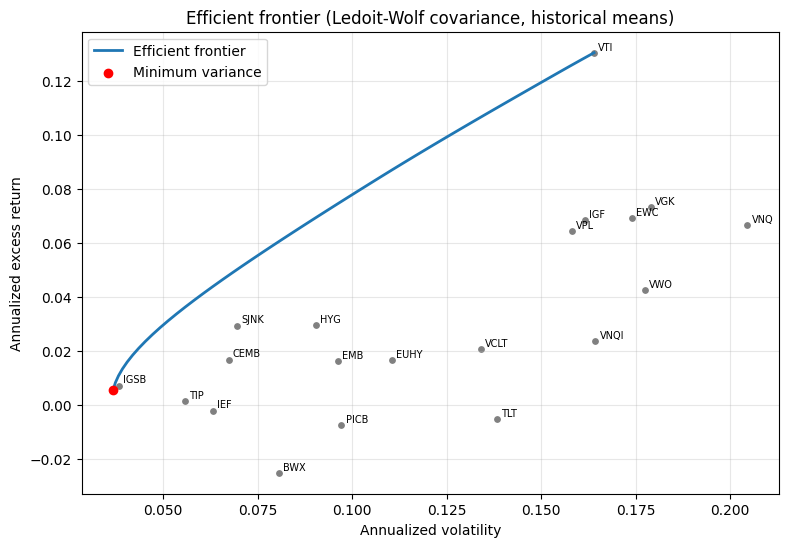

In [6]:
import matplotlib.pyplot as plt

frontier_vol = np.sqrt(efficient_frontier)   # variances -> volatilities
frontier_ret = y_axis                         # target returns

plt.figure(figsize=(9, 6))
plt.plot(frontier_vol, frontier_ret, lw=2, label="Efficient frontier")

# minimum-variance portfolio
plt.scatter(vol, min_vol_ret, color="red", zorder=3, label="Minimum variance")

# individual funds
asset_vol = np.sqrt(np.diag(lw_cov))
plt.scatter(asset_vol, exp_ret, s=15, color="0.5")
for ticker, x, y in zip(exp_ret.index, asset_vol, exp_ret):
    plt.annotate(ticker, (x, y), fontsize=7, xytext=(3, 2), textcoords="offset points")

plt.xlabel("Annualized volatility")
plt.ylabel("Annualized excess return")
plt.title("Efficient frontier (Ledoit-Wolf covariance, historical means)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
from pce import views

w_mkt = data.load_market_weights()
P, Q = views.views_to_PQ(lw_cov.index)
pi = optimize.black_litterman(lw_cov, w_mkt)[1]          
w_bl, mu_bl = optimize.black_litterman(lw_cov, w_mkt, P, Q)

pd.DataFrame({"View": Q, "Prior": P @ pi, "Posterior": P @ mu_bl}).style.format("{:.2%}")

,View,Prior,Posterior
JPM: US large cap 7.5% vs int. Treasuries 4.6%,2.90%,5.16%,3.91%
JPM: EM equity 7.1% vs int. Treasuries 4.6%,2.50%,4.29%,3.28%
JPM: US IG credit 6.1% vs int. Treasuries 4.6%,1.50%,1.27%,1.25%
JPM: US high yield 6.7% vs int. Treasuries 4.6%,2.10%,2.18%,1.68%
Vanguard: dev. ex-US equity 6.3% vs US equity 5.8%,0.50%,-0.70%,-0.06%
Vanguard: EM equity 4.7% vs US equity 5.8%,-1.10%,-0.86%,-0.64%
Vanguard: EM sovereign 6.9% vs US high yield 5.9%,1.00%,-0.22%,0.38%


In [8]:
portfolios = pd.DataFrame({"Market": w_mkt, "Min variance": w, "Black-Litterman": w_bl})

stats = pd.DataFrame({
    name: {
        "Expected excess return (historical)": p @ exp_ret,
        "Expected excess return (BL)": p @ mu_bl,
        "Volatility": np.sqrt(p @ lw_cov @ p),
    }
    for name, p in portfolios.items()
}).T

display(portfolios.style.format("{:.1%}"))
display(stats.style.format("{:.2%}"))

,Market,Min variance,Black-Litterman
VTI,60.4%,0.0%,24.7%
EWC,0.4%,0.0%,6.6%
VGK,3.1%,0.0%,11.8%
VPL,0.9%,0.0%,6.5%
VWO,11.2%,0.0%,0.0%
IEF,4.8%,7.6%,0.0%
TLT,5.0%,0.0%,4.1%
BWX,0.1%,0.0%,0.0%
EMB,1.8%,0.0%,35.3%
IGSB,2.3%,79.5%,0.0%


,Expected excess return (historical),Expected excess return (BL),Volatility
Market,9.08%,3.60%,13.00%
Min variance,0.56%,0.67%,3.68%
Black-Litterman,5.94%,3.37%,11.38%


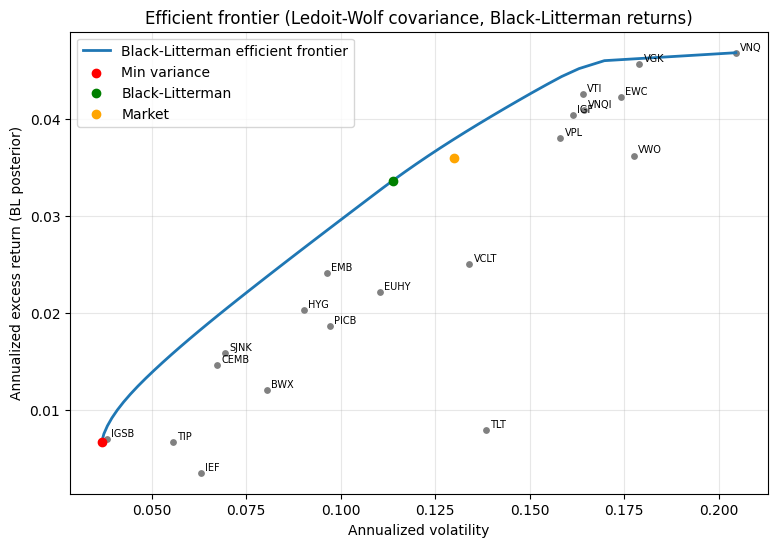

In [9]:
bl_y_axis = np.linspace(w @ mu_bl, mu_bl.max())
bl_frontier = [optimize.min_variance(lw_cov, 1, mu_bl, x)[1] for x in bl_y_axis]

plt.figure(figsize=(9, 6))
plt.plot(np.sqrt(bl_frontier), bl_y_axis, lw=2, label="Black-Litterman efficient frontier")

for name, color in [("Min variance", "red"), ("Black-Litterman", "green"), ("Market", "orange")]:
    p = portfolios[name]
    plt.scatter(np.sqrt(p @ lw_cov @ p), p @ mu_bl, color=color, zorder=3, label=name)

# individual funds
plt.scatter(asset_vol, mu_bl, s=15, color="0.5")
for ticker, x, y in zip(mu_bl.index, asset_vol, mu_bl):
    plt.annotate(ticker, (x, y), fontsize=7, xytext=(3, 2), textcoords="offset points")

plt.xlabel("Annualized volatility")
plt.ylabel("Annualized excess return (BL posterior)")
plt.title("Efficient frontier (Ledoit-Wolf covariance, Black-Litterman returns)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()